# SaaS Subscription Analytics — Complete Solution

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
DATA=Path('../02_Data/Clean_Reference'); OUT=Path('../07_Solution_Outputs')
accounts=pd.read_csv(DATA/'dim_accounts.csv',parse_dates=['signup_date'])
monthly=pd.read_csv(DATA/'fact_monthly_account_snapshot.csv',parse_dates=['month'])
invoices=pd.read_csv(DATA/'fact_invoices.csv',parse_dates=['invoice_month','due_date','paid_date'])

In [2]:
latest=monthly[monthly.month.eq(monthly.month.max())]
active=latest[latest.churned_flag.eq(0)]
print('Latest month:',monthly.month.max().date())
print('Active logos:',active.account_id.nunique())
print('MRR £:',round(active.mrr_gbp.sum(),2))
print('ARR £:',round(active.mrr_gbp.sum()*12,2))

Latest month: 2026-09-01
Active logos: 4328
MRR £: 91045960.53
ARR £: 1092551526.36


## NRR / GRR trend

,month,starting_mrr_gbp,expansion_mrr_gbp,contraction_mrr_gbp,churn_mrr_gbp,nrr,grr,logo_retention
32,2025-10-01,83998123.28,1949181.22,964250.50,1497938.47,0.993893,0.970688,0.975872
33,2025-11-01,86207921.58,1898069.29,1126364.11,2167936.30,0.983804,0.961787,0.976324
34,2025-12-01,87878788.71,2037420.41,1113631.68,1453100.07,0.993977,0.970792,0.975353
35,2026-01-01,89821730.17,1909986.10,1215118.38,1096860.98,0.995525,0.974260,0.976195
36,2026-02-01,92552836.17,2231991.52,1111541.59,1588630.13,0.994941,0.970826,0.973759
37,2026-03-01,94558545.66,2047912.04,1169650.17,1265933.49,0.995900,0.974243,0.977943
38,2026-04-01,97529868.89,2147867.40,1219378.49,2442243.19,0.984479,0.962456,0.969733
39,2026-05-01,96016114.61,1969015.36,1227488.65,1918020.65,0.987747,0.967240,0.973247
40,2026-06-01,94839620.67,2145542.15,1079451.29,2055089.30,0.989572,0.966949,0.973969
41,2026-07-01,93850622.23,2056312.10,1188378.26,1516195.98,0.993093,0.971182,0.973273


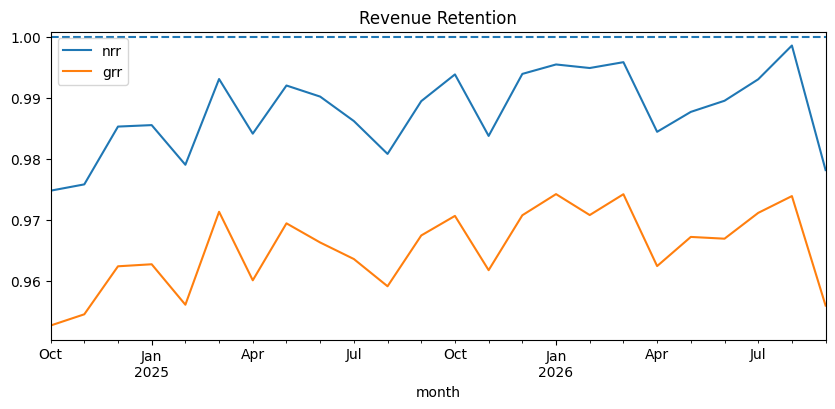

In [3]:
k=pd.read_csv(OUT/'monthly_saas_kpis.csv',parse_dates=['month'])
display(k.tail(12))
k.set_index('month')[['nrr','grr']].tail(24).plot(figsize=(10,4),title='Revenue Retention'); plt.axhline(1,ls='--'); plt.show()

## Customer health

In [4]:
health=pd.read_csv(OUT/'customer_health_scores.csv')
display(health.groupby('health_band').agg(accounts=('account_id','nunique'),ARR=('annual_arr_gbp','sum'),risk_ARR=('risk_arr_gbp','sum'),avg_health=('health_score','mean')).sort_values('avg_health'))

,accounts,ARR,risk_ARR,avg_health
health_band,,,,
At Risk,257,4.712566e+07,47125662.6,62.038521
Watch,2869,7.082141e+08,0.0,73.947612
Healthy,1202,3.372118e+08,0.0,83.382612


## Pricing leakage

In [5]:
leak=pd.read_csv(OUT/'pricing_discount_leakage.csv')
print('Annualized excess-discount leakage £:',round(leak.estimated_annual_discount_leakage_gbp.sum(),2))
display(leak.head(10))

Annualized excess-discount leakage £: 20895381.59


,account_id,plan_id,seats,discount_pct,standard_discount_pct,excess_discount_pct,estimated_annual_discount_leakage_gbp
0,ACC004911,PLN_ENT,11892,0.257017,0.16,0.097017,415339.59
1,ACC002421,PLN_ENT,7612,0.283673,0.16,0.123673,338904.59
2,ACC003926,PLN_ENT,8239,0.254444,0.16,0.094444,280124.25
3,ACC000016,PLN_ENT,5502,0.297440,0.16,0.137440,272230.07
4,ACC000164,PLN_ENT,6400,0.263147,0.16,0.103147,237651.08
5,ACC003295,PLN_ENT,7147,0.250997,0.16,0.090997,234128.61
6,ACC006227,PLN_ENT,18161,0.194227,0.16,0.034227,223771.51
7,ACC001782,PLN_ENT,5732,0.260848,0.16,0.100848,208101.61
8,ACC001423,PLN_ENT,6723,0.245385,0.16,0.085385,206655.72
9,ACC006870,PLN_ENT,6158,0.247371,0.16,0.087371,193690.66


## Acquisition economics

In [6]:
cac=pd.read_csv(OUT/'cac_by_channel_month.csv')
display(cac.groupby('acquisition_channel').agg(spend=('marketing_sales_spend_gbp','sum'),new_customers=('new_customers','sum')).assign(CAC=lambda d:d.spend/d.new_customers).sort_values('CAC'))

,spend,new_customers,CAC
acquisition_channel,,,
Referral,1270982.73,808.0,1572.998428
Inbound,6607483.68,2397.0,2756.563905
Partner,3693212.36,1310.0,2819.246076
Product-Led,5008574.02,1274.0,3931.376782
Events,2697418.08,619.0,4357.702876
Outbound SDR,8369680.52,1592.0,5257.337010


## Interpretable churn propensity

In [7]:
last=monthly.sort_values('month').groupby('account_id').tail(1).copy()
pay=invoices.groupby('account_id').agg(failed=('payment_status',lambda s:(s=='Failed').sum()),late=('payment_status',lambda s:(s=='Late').sum())).reset_index()
f=last.merge(pay,on='account_id',how='left').fillna({'failed':0,'late':0})
cols=['seat_utilization','support_tickets','critical_tickets','avg_resolution_hours','discount_pct','failed','late','seats']
X=f[cols].fillna(f[cols].median()); y=f.churned_flag
sc=StandardScaler(); xs=sc.fit_transform(X)
model=LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42).fit(xs,y)
prob=model.predict_proba(xs)[:,1]
print('AUC:',round(roc_auc_score(y,prob),3))
display(pd.DataFrame({'feature':cols,'coefficient':model.coef_[0]}).sort_values('coefficient',ascending=False))

AUC: 0.634


,feature,coefficient
5,failed,0.039929
1,support_tickets,0.027122
3,avg_resolution_hours,0.024006
2,critical_tickets,-0.038662
6,late,-0.053445
4,discount_pct,-0.110313
7,seats,-0.110722
0,seat_utilization,-0.454170


## Expansion / renewal priority lists

In [8]:
display(pd.read_csv(OUT/'expansion_candidates.csv').head(20))
display(pd.read_csv(OUT/'next_90_day_renewal_priorities.csv').head(20))

,account_id,current_mrr,prior_mrr,latest_discount,seats,active_users,current_utilization,plan_id,avg_utilization,avg_nps,support_tickets,critical_tickets,avg_resolution_hours,failed_payments,late_payments,segment,industry,region,acquisition_channel,account_manager_id,usage_component,nps_component,support_component,payment_component,growth_component,health_score,health_band,annual_arr_gbp,risk_arr_gbp,priority_score
0,ACC006994,363587.78,364055.26,0.146568,6455,5980,0.9264,PLN_ENT,0.909867,10.0,7,0,8.303333,0.0,0.0,Strategic,Education,Benelux,Events,AM024,0.909867,1.0,1.000000,1.00,0.498716,89.3,Healthy,4363053.36,0.0,99.9
1,ACC006241,124437.94,124652.79,0.187477,5105,4772,0.9348,PLN_ENT,0.944800,10.0,6,0,8.713333,0.0,0.0,Strategic,Technology,France,Inbound,AM032,0.944800,1.0,1.000000,1.00,0.498276,90.5,Healthy,1493255.28,0.0,97.9
2,ACC001714,313740.00,297567.05,0.151653,4931,4581,0.9290,PLN_ENT,0.910600,8.0,4,1,6.020000,0.0,0.0,Strategic,Manufacturing,North America,Partner,AM009,0.910600,0.8,0.820000,1.00,0.554351,82.9,Healthy,3764880.00,0.0,97.2
3,ACC006491,147864.46,129733.46,0.226246,2548,2203,0.8646,PLN_ENT,0.885300,10.0,2,0,3.706667,0.0,0.0,Enterprise,Media,UK&I,Outbound SDR,AM035,0.885300,1.0,1.000000,1.00,0.639756,90.6,Healthy,1774373.52,0.0,97.0
4,ACC005588,382079.87,350183.64,0.168324,9281,8180,0.8814,PLN_ENT,0.900000,7.0,12,1,5.093333,0.0,0.0,Strategic,Professional Services,North America,Product-Led,AM033,0.900000,0.7,0.820000,1.00,0.591084,81.1,Healthy,4584958.44,0.0,96.9
5,ACC001459,148513.16,152215.66,0.079391,3259,3226,0.9899,PLN_ENT,0.914033,9.0,1,0,3.610000,0.0,1.0,Enterprise,Retail,Southern Europe,Outbound SDR,AM017,0.914033,0.9,1.000000,0.92,0.475676,86.2,Healthy,1782157.92,0.0,96.2
6,ACC005247,281672.74,258168.23,0.128687,5012,4597,0.9172,PLN_ENT,0.848333,10.0,6,1,9.670000,0.0,1.0,Strategic,Energy,France,Inbound,AM009,0.848333,1.0,0.820000,0.92,0.591043,84.4,Healthy,3380072.88,0.0,95.8
7,ACC000313,257958.75,264865.66,0.175172,5957,5205,0.8738,PLN_ENT,0.841567,9.0,11,0,7.396667,0.0,0.0,Strategic,Financial Services,Southern Europe,Outbound SDR,AM031,0.841567,0.9,1.000000,1.00,0.473923,84.6,Healthy,3095505.00,0.0,95.5
8,ACC006114,91951.42,89484.17,0.018462,1487,1209,0.8130,PLN_ENT,0.900200,10.0,2,0,4.100000,0.0,0.0,Enterprise,Financial Services,North America,Partner,AM033,0.900200,1.0,1.000000,1.00,0.527572,89.4,Healthy,1103417.04,0.0,95.5
9,ACC005878,370848.10,376267.98,0.187912,7080,5554,0.7845,PLN_ENT,0.802867,9.0,10,0,8.316667,0.0,0.0,Strategic,Financial Services,Southern Europe,Product-Led,AM017,0.802867,0.9,1.000000,1.00,0.485596,83.4,Healthy,4450177.20,0.0,95.2


,subscription_id,account_id,initial_plan_id,start_date,cancellation_date,subscription_status,billing_frequency,contract_term_months,initial_discount_pct,primary_churn_reason,account_manager_id,health_score,health_band,annual_arr_gbp,next_renewal_date,renewal_priority_score
0,SUB0003024,ACC003024,PLN_ENT,2025-01-01,NaN,Active,Annual,12,0.1266,NaN,AM027,53.2,At Risk,1633614.72,2027-01-01,85.4
1,SUB0005686,ACC005686,PLN_ENT,2025-07-04,NaN,Active,Monthly,1,0.1631,NaN,AM030,60.1,At Risk,1901324.04,2026-11-04,83.0
2,SUB0002956,ACC002956,PLN_ENT,2026-03-04,NaN,Active,Monthly,1,0.1963,NaN,AM032,59.2,At Risk,1275487.80,2026-11-04,81.6
3,SUB0007665,ACC007665,PLN_ENT,2023-12-26,NaN,Active,Monthly,1,0.1629,NaN,AM015,73.6,Watch,4849522.44,2026-10-26,81.2
4,SUB0003970,ACC003970,PLN_ENT,2025-10-21,NaN,Active,Annual,12,0.1801,NaN,AM013,66.2,Watch,2164935.72,2026-10-21,80.9
5,SUB0000891,ACC000891,PLN_ENT,2023-03-25,NaN,Active,Monthly,1,0.1330,NaN,AM023,69.1,Watch,2858560.92,2026-10-25,80.8
6,SUB0001221,ACC001221,PLN_ENT,2024-12-02,NaN,Active,Annual,24,0.2210,NaN,AM005,70.0,Watch,2929414.56,2026-12-02,80.5
7,SUB0004574,ACC004574,PLN_ENT,2025-04-19,NaN,Active,Monthly,1,0.1843,NaN,AM030,68.6,Watch,2414430.12,2026-10-19,80.3
8,SUB0004571,ACC004571,PLN_ENT,2023-11-10,NaN,Active,Monthly,1,0.1215,NaN,AM006,56.5,At Risk,610937.76,2026-10-10,79.5
9,SUB0000852,ACC000852,PLN_ENT,2025-10-21,NaN,Active,Annual,12,0.1229,NaN,AM005,68.1,Watch,1886366.76,2026-10-21,79.4


## Final management story
See `06_Consulting_Workflow/05_Executive_Story_Solution.md`.